In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
from time import perf_counter

import marimo as mo
import matplotlib.pyplot as plt
import numpy as np

import pyrite

with mo.status.spinner(title="Preparing pinned reference tables"):
    _ = pyrite.fetch_tables()
tables_ready = True

# Classical coherent phase tracking and bunch enhancement

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/17-classical-coherent-phase-tracking.py)

PXR/CBS fields from **segments of one electron** interfere before squaring.
A physical bunch can add **cross-electron** terms, scaling up to $N^2$ in
the equal-field, phase-matched limit. The coherent estimator still reports
*per-incident-electron* yield; its ideal inter-electron enhancement is $N$
relative to the corresponding **one-electron coherent** self term. A ratio
to the segment-incoherent spectrum has no universal $N$ upper bound.

We compare an ordinary Gaussian bunch with a **target-line-matched train**
of microbunches, and then suppress enhancement with a transverse spot.
This is a reduced-history learning example, not a precision prediction.
The physical population $N=Q/e$ is distinct from the number $M$ of
simulated Monte Carlo histories.

The first execution compiles kernels. On CPU, coherent field/time scoring
can be substantially slower than ordinary spectra; the elapsed times below
are measured on **your** machine, not a claimed benchmark. For CUDA set
`PYRITE_MC_BACKEND=cuda` before the PyRITE import, install
`pyrite-mc[nvidia]`, and restart the kernel.

In [ ]:
assert tables_ready
from scipy.constants import elementary_charge, hbar

from pyrite import simulate
from pyrite.beams import Beam, BunchLength, LongitudinalDistribution, PointSpot, TransverseSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector, EnergyBins
from pyrite.geometry import Slab
from pyrite.units import ureg

# Keep this workload modest. Re-measure CPU time before increasing M or grid size.
# Covers the first HOPG basal PXR line near 0.85 keV. Narrow to control CPU cost.
energy_eV = np.linspace(700.0, 1100.0, 401)
numerics = Numerics(
    sampling=FixedSampling(cxr_electrons=256, brem_electrons=16),
    cxr_reflections=CxrReflections(n_families=1),
    energy_bins=EnergyBins().with_cxr_energies(energy_eV * ureg.eV),
    seed=777,
    temporal_profile=True,
)
physics = Physics(emission=("incoherent", "coherent"), brem_source="none")
target = Slab(
    "hopg",
    thickness=100 * ureg.nm,
    tilt=30 * ureg.degree,
    footprint=None,
)
detector = Detector(observation_angle=135 * ureg.degree)
charge_pc = 1e-5
# The microtrain uses a 1 fs envelope, not an attosecond Gaussian bunch.
train = LongitudinalDistribution(
    kind="microtrain",
    envelope_rms_fs=1.0,
    retained_coherence=0.9,
    spacing_periods=1,
    modulation_depth=1.0,
    timing_jitter_fs=0.0,
)
long_gaussian = BunchLength(rms_duration=1.0 * ureg.fs)


def make_beam(longitudinal, *, charge=charge_pc, spot=None):
    return Beam(
        kinetic_energy=30 * ureg.keV,
        transverse=PointSpot() if spot is None else spot,
        longitudinal=longitudinal,
        bunch_charge=charge * ureg.pC,
        repetition_rate=5 * ureg.kHz,
    )


def simulate_case(longitudinal, *, charge=charge_pc, spot=None):
    return simulate(
        make_beam(longitudinal, charge=charge, spot=spot),
        target,
        detector,
        physics=physics,
        numerics=numerics,
    )


# Analytic Gaussian bunching factor: F_z(E) = exp[-(E sigma_t / hbar)^2].
hbar_eV_fs = hbar / elementary_charge * 1e15
physical_electrons = charge_pc * 1e-12 / elementary_charge

In [ ]:
assert tables_ready
# Both CXR modes in each result share a single set of transported histories.
samples = {}
elapsed = {}
configurations = {
    "train / point": dict(longitudinal=train),
    "train / low charge": dict(longitudinal=train, charge=charge_pc / 10),
    "Gaussian / point": dict(longitudinal=long_gaussian),
    "train / finite spot": dict(longitudinal=train, spot=TransverseSpot(fwhm_x=0.5 * ureg.nm)),
}
with mo.status.progress_bar(total=len(configurations), title="Scoring coherent CXR") as progress:
    for _label, options in configurations.items():
        t0 = perf_counter()
        samples[_label] = simulate_case(**options)
        elapsed[_label] = perf_counter() - t0
        progress.update(subtitle=f"{_label}: {elapsed[_label]:.1f} s")
assert all(item.cxr.coherent is not None and item.temporal is not None for item in samples.values())

In [ ]:
mo.md(
    "**Measured local wall times** (including any first-run compilation): "
    + ", ".join(f"{name}: {seconds:.1f} s" for name, seconds in elapsed.items())
)

**Measured local wall times** (including any first-run compilation): train / point: 6.2 s, train / low charge: 0.7 s, Gaussian / point: 0.7 s, train / finite spot: 0.7 s

findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeOneSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeTwoSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeThreeSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeFourSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeFiveSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not

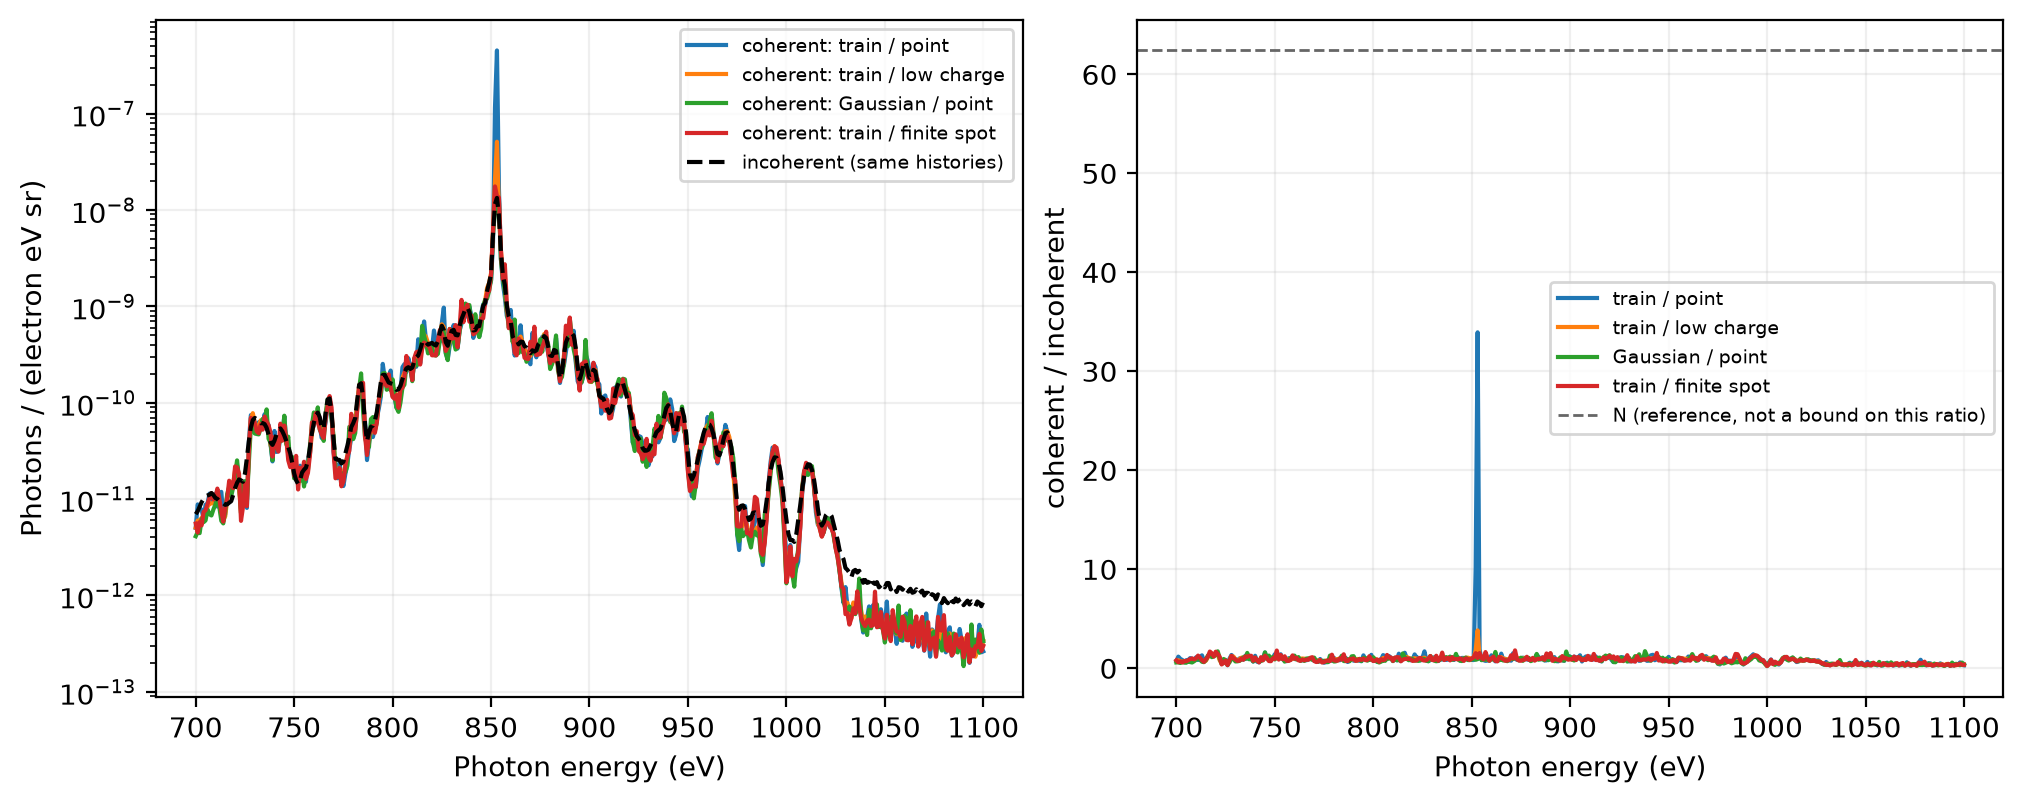

In [ ]:
fig_spectra, (ax_s, ax_r) = plt.subplots(1, 2, figsize=(10, 3.9), layout="constrained")
for label, result in samples.items():
    incoherent = result.cxr.incoherent
    coherent = result.cxr.coherent
    _energy = incoherent.photon_energy_eV
    assert coherent is not None
    ax_s.plot(_energy, coherent.density, label=f"coherent: {label}")
    # Compare only at valid spectral bins; do not hide signed estimator errors.
    ratio = np.divide(
        coherent.density,
        incoherent.density,
        out=np.full_like(coherent.density, np.nan),
        where=incoherent.density > 0,
    )
    ax_r.plot(_energy, ratio, label=label)
base = samples["train / point"].cxr.incoherent
ax_s.plot(base.photon_energy_eV, base.density, "k--", label="incoherent (same histories)")
ax_s.set(yscale="log", xlabel="Photon energy (eV)", ylabel="Photons / (electron eV sr)")
ax_r.set(xlabel="Photon energy (eV)", ylabel="coherent / incoherent")
ax_r.axhline(
    physical_electrons,
    color="0.4",
    ls="--",
    lw=1,
    label="N (reference, not a bound on this ratio)",
)
for _ax in (ax_s, ax_r):
    _ax.grid(alpha=0.2)
    _ax.legend(fontsize=7)
fig_spectra  # noqa: B018

## Read the two kinds of coherence separately

Intra-electron coherence sums the *complex amplitudes* from a single
trajectory's segments. Inter-electron enhancement involves cross terms
between distinct physical electrons. The incoherent and coherent spectra
in each result use the **same** simulated trajectories, rather than an
independently seeded pair of simulations. The Gaussian bunch spreads arrival
phases; a phase-locked microtrain preserves a Fourier component at its
matched X-ray line despite having a much longer envelope.

The transverse factor for an independent Gaussian spot is approximately
$F_\perp=\exp[-|\mathbf q_\perp|^2\sigma_\perp^2]$ with
$\mathbf q_\perp=(\omega\hat{\mathbf n}+\mathbf g)_\perp$ in inverse length.
Even sub-nm spots can strongly suppress coherence at X-ray wavenumbers.
This plot compares the **modeled output**, not a claim of validated source
brightness. Signed-pair coherent estimators can be noisy near zero signal.

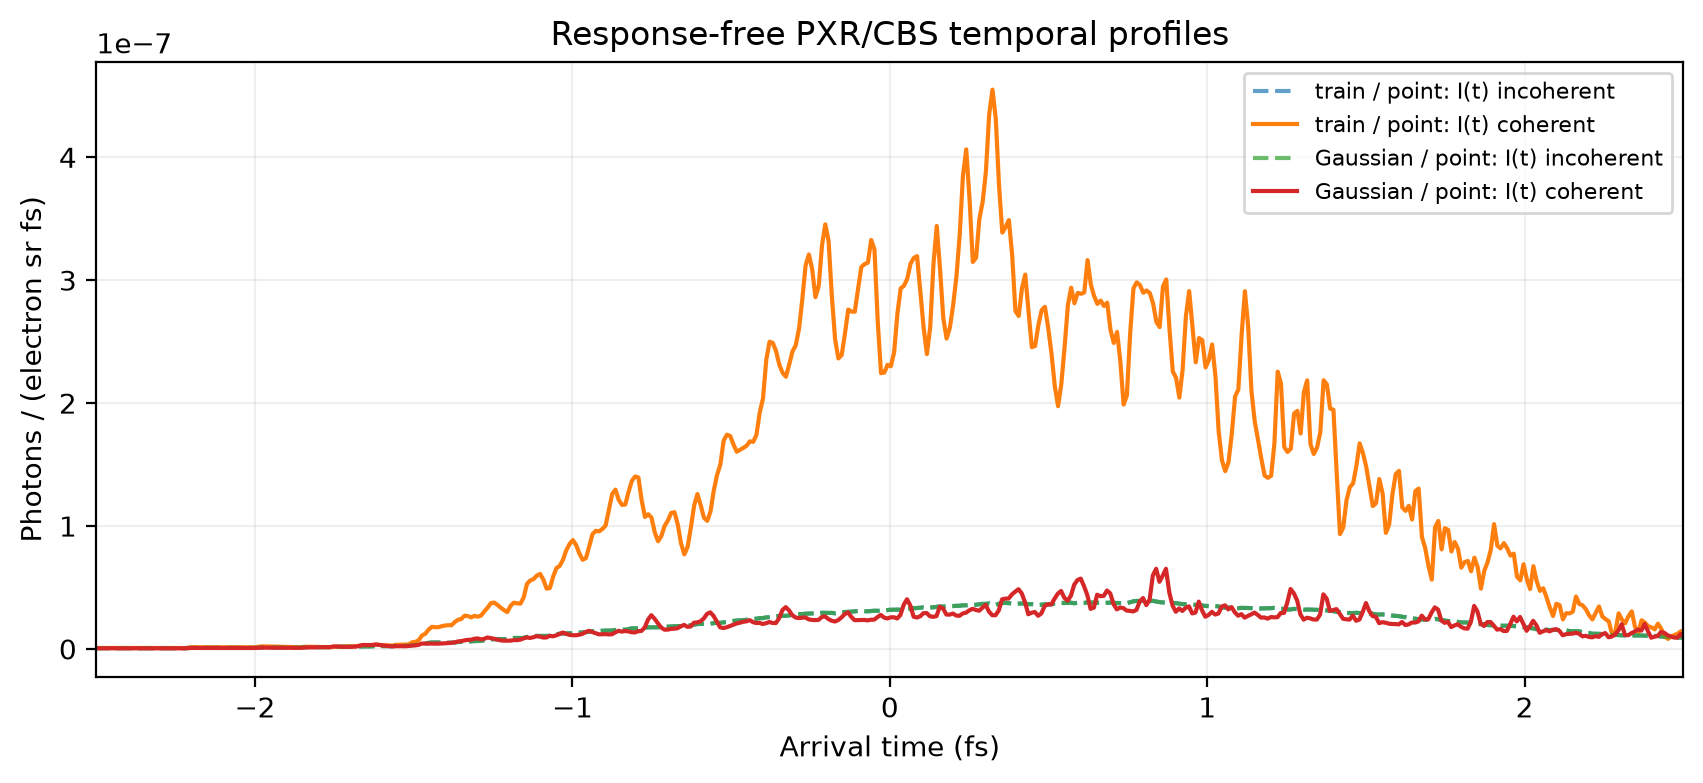

In [ ]:
fig_time, _ax = plt.subplots(figsize=(8.4, 3.8), layout="constrained")
for _label in ("train / point", "Gaussian / point"):
    temporal = samples[_label].temporal
    assert temporal is not None
    _ax.plot(
        temporal.time_fs,
        temporal.incoherent,
        ls="--",
        alpha=0.7,
        label=f"{_label}: I(t) incoherent",
    )
    if temporal.coherent is not None:
        _ax.plot(temporal.time_fs, temporal.coherent, label=f"{_label}: I(t) coherent")
_ax.set(
    xlabel="Arrival time (fs)",
    ylabel="Photons / (electron sr fs)",
    title="Response-free PXR/CBS temporal profiles",
)
_ax.grid(alpha=0.2)
_ax.legend(fontsize=8)
# Inspect the physical arrival window, rather than the entire FFT period.
_ax.set_xlim(-2.5, 2.5)
fig_time  # noqa: B018

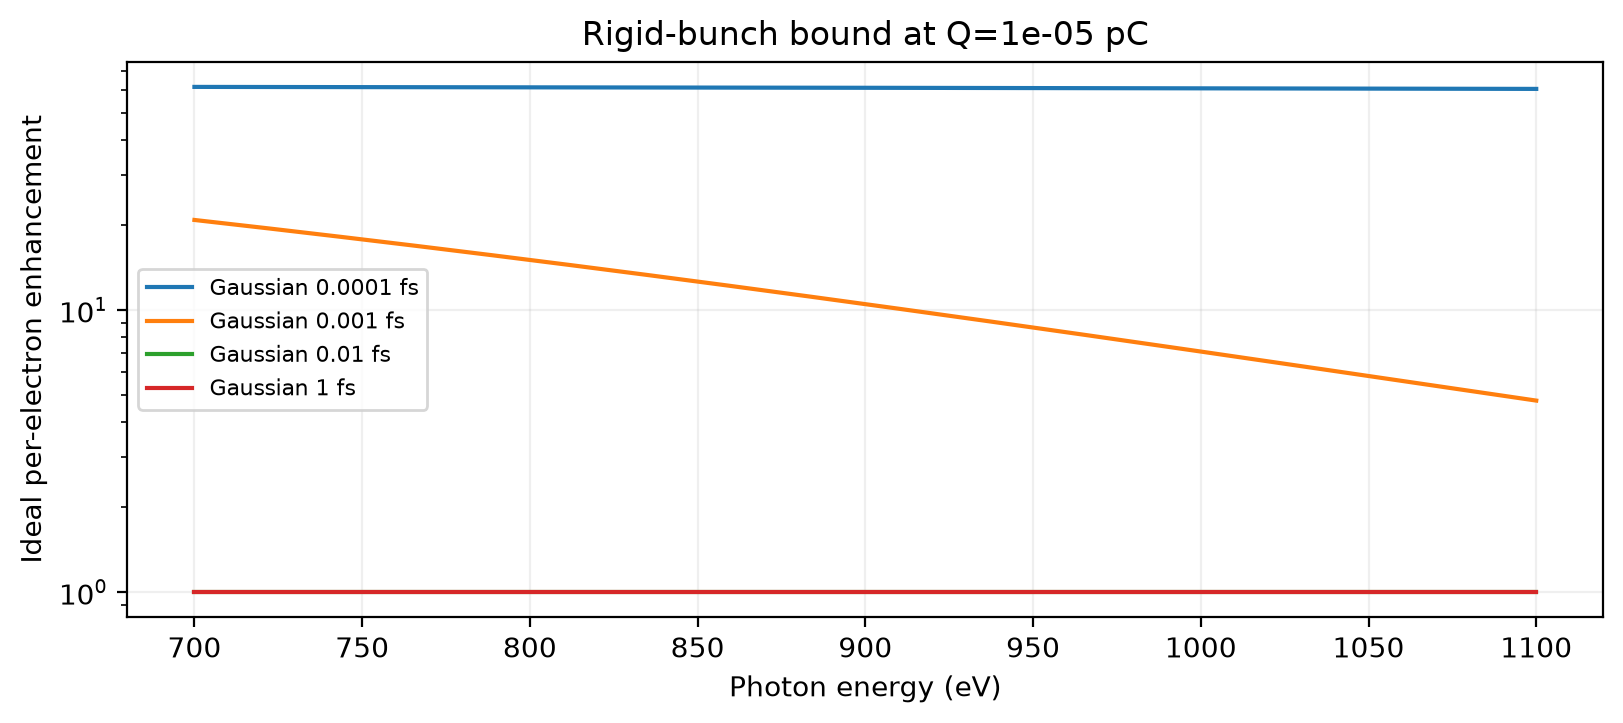

In [ ]:
# An analytic reference for identical emitters (not a bound on CXR mode ratios).
# It must not be interpreted as the Monte Carlo spectrum of a microtrain.
_energy = samples["train / point"].cxr.incoherent.photon_energy_eV
fig_form, _ax = plt.subplots(figsize=(8.0, 3.5), layout="constrained")
for sigma_fs in (0.0001, 0.001, 0.01, 1.0):
    fz = np.exp(-((_energy * sigma_fs / hbar_eV_fs) ** 2))
    _ax.plot(_energy, 1 + (physical_electrons - 1) * fz, label=f"Gaussian {sigma_fs:g} fs")
_ax.set(
    xlabel="Photon energy (eV)",
    ylabel="Ideal per-electron enhancement",
    yscale="log",
    title=f"Rigid-bunch bound at Q={charge_pc:g} pC",
)
_ax.grid(alpha=0.2)
_ax.legend(fontsize=8)
fig_form  # noqa: B018

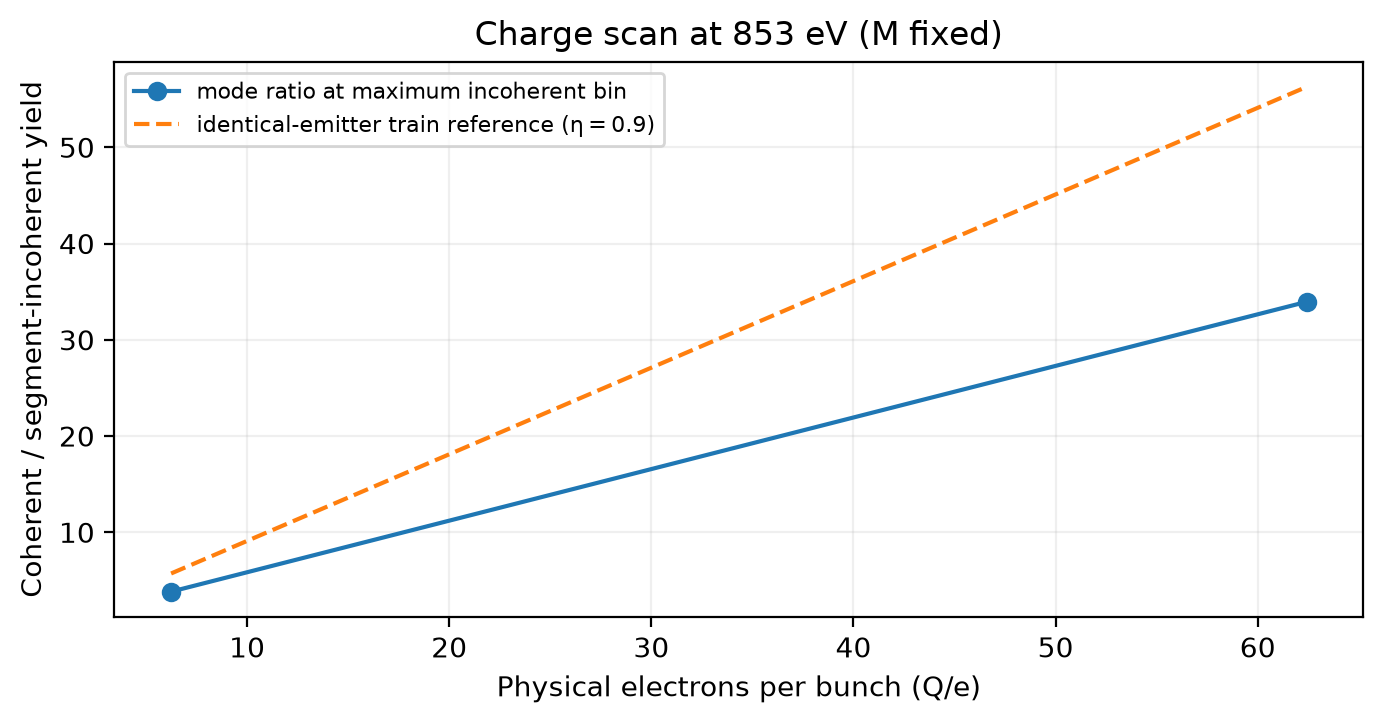

In [ ]:
# Two charges share fixed M and seed, separating population from MC histories.
high = samples["train / point"]
low = samples["train / low charge"]
energy = high.cxr.incoherent.photon_energy_eV
index = int(np.argmax(high.cxr.incoherent.density))
charges = np.array([charge_pc / 10, charge_pc])  # pC
n_physical = physical_electrons * charges / charge_pc
measured = np.array(
    [
        low.cxr.coherent.density[index] / low.cxr.incoherent.density[index],
        high.cxr.coherent.density[index] / high.cxr.incoherent.density[index],
    ]
)
fig_charge, _ax = plt.subplots(figsize=(6.8, 3.5), layout="constrained")
_ax.plot(n_physical, measured, "o-", label="mode ratio at maximum incoherent bin")
_ax.plot(
    n_physical,
    1 + (n_physical - 1) * 0.9,
    "--",
    label=r"identical-emitter train reference ($\eta=0.9$)",
)
_ax.set(
    xlabel="Physical electrons per bunch (Q/e)",
    ylabel="Coherent / segment-incoherent yield",
    title=f"Charge scan at {energy[index]:.0f} eV (M fixed)",
)
_ax.grid(alpha=0.2)
_ax.legend(fontsize=8)
fig_charge  # noqa: B018

## Interpretation and validation scope

For $N$ **identical** radiators, the per-electron enhancement is
$1+(N-1)|F(\omega)|^2$, with a Gaussian *intensity* form factor
$|F|^2=\exp[-(\omega\sigma_t)^2]$. A full-depth, zero-jitter microtrain
targets a specified bunching factor *at the selected catalog basal line*;
it does **not** follow the smooth Gaussian curve at neighboring energies.
Real electrons follow different scattering trajectories, so that rigid-field
formula is a reference curve, not a prediction of the simulated enhancement.
The factor for a finite transverse spot multiplies the longitudinal factor
only under the model's offset-independence assumptions.

`Result.temporal` is an opt-in **source** diagnostic, not a detector waveform
or a time-resolution model. Its coherent estimator can have negative *bins*
from cross terms; never clip them before integrating. The FFT time resolution
is limited by the energy bandwidth, and an inverse-FFT period need not
represent a measured pulse duration.

This notebook demonstrates modeled behavior, **not independent validation
sign-off**. Consult [coherent-emission](../../physics/radiation-physics/coherent-emission.md),
[temporal-intensity-profile](../../physics/radiation-physics/temporal-intensity-profile.md),
[longitudinal structure](../../physics/beam-transport/longitudinal-structure.md), and
validations [coherent-inter-electron-decoherence](../../validation/radiation-physics/coherent-inter-electron-decoherence.md)
and [coherent-physical-bunch-population](../../validation/radiation-physics/coherent-physical-bunch-population.md).
Before publishing a numerical capture, measure CPU workload, rerun on the
intended backend, and inspect the coherent sampling error and temporal grid.

## Continue learning

See [Transition radiation](10-transition-radiation.ipynb)
and [Coherent-emission physics](../../physics/radiation-physics/coherent-emission.md).

{download}`Download canonical Marimo notebook <../17-classical-coherent-phase-tracking.py>`